Running combustion equilibrium (GOx/Propane, O/F=2.2, Pc=50 psia)...
Propane phase at 50 psia / 293 K: Gas  (Psat = 120.8 psia)

  COMBUSTION EQUILIBRIUM  (GOx/Propane, O/F=2.2, Pc=50 psia)
  Tc              = 3113.9 K  (2840.7 C)
  gamma (frozen)  = 1.2322
  gamma (equil)   = 1.1694
  Mw              = 19.15 g/mol
  c*              = 1600.0 m/s

  mdot total      = 46.1 g/s  (from 0.65" throat)
  mdot GOx        = 31.7 g/s
  mdot Propane    = 14.4 g/s

  GOx orifice D   = 8.04 mm  (60 psia inlet, 10 psi dP)
  Propane orif. D = 4.91 mm  (60 psia inlet, 10 psi dP)

  Top combustion products (mole fractions):
    CO           0.3383
    H2O          0.3042
    H2           0.1961
    CO2          0.0688
    H            0.0528
    OH           0.0320

Using mdot — GOx: 31.7 g/s  |  Propane: 14.4 g/s
Using orifice D — GOx: 8.04 mm  |  Propane: 4.91 mm


Sweeping GOx regulator pressure...
Sweeping Propane regulator pressure...

  REGULATOR SIZING RESULTS  (placeholder Cv/K values)
  GOx   

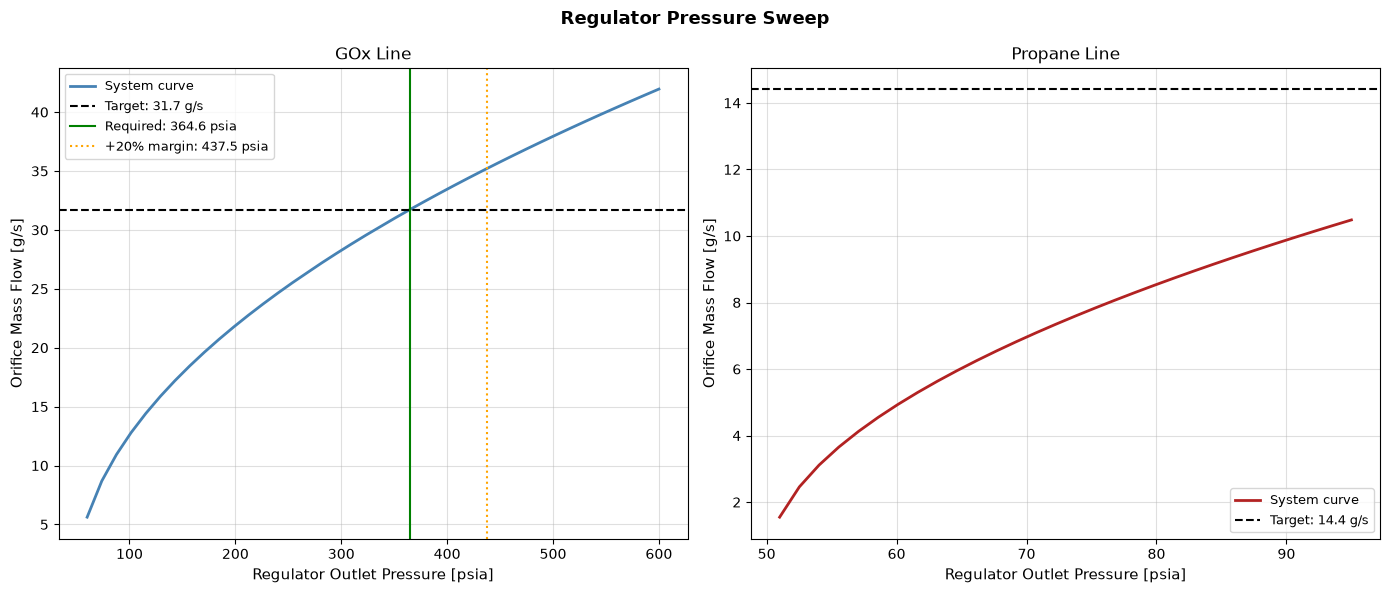


Solving at required regulator setpoints...
  NOTE: Propane cannot deliver 14.4 g/s with current Cv values
  and 100 psia tank. Plotting at 95.0 psia. Action: use higher-Cv
  FMV/FPV valves or raise tank pressure once hardware is selected.

  GOx Steady State
  Node Pressures:
    GOx Tank                        2000.00 psia
    Post-Filter/Vent-1 Tee          1973.82 psia
    Post-OPV                        1314.02 psia
    Post-Reg/Vent-2 Tee              364.57 psia
    Post-OMV                         363.82 psia
    Post-Arrestor                     90.90 psia
    Chamber                           50.00 psia
    Ambient                           14.70 psia
  Branch Mass Flows:
    O-FILT                   187.05 g/s
    O-VENT-1                   0.00 g/s
    OPV                      187.05 g/s
    O-REG                    187.05 g/s
    O-VENT-2                   0.00 g/s
    OMV                       31.71 g/s
    O-ARREST                  31.71 g/s
    O-INJ-ORF                

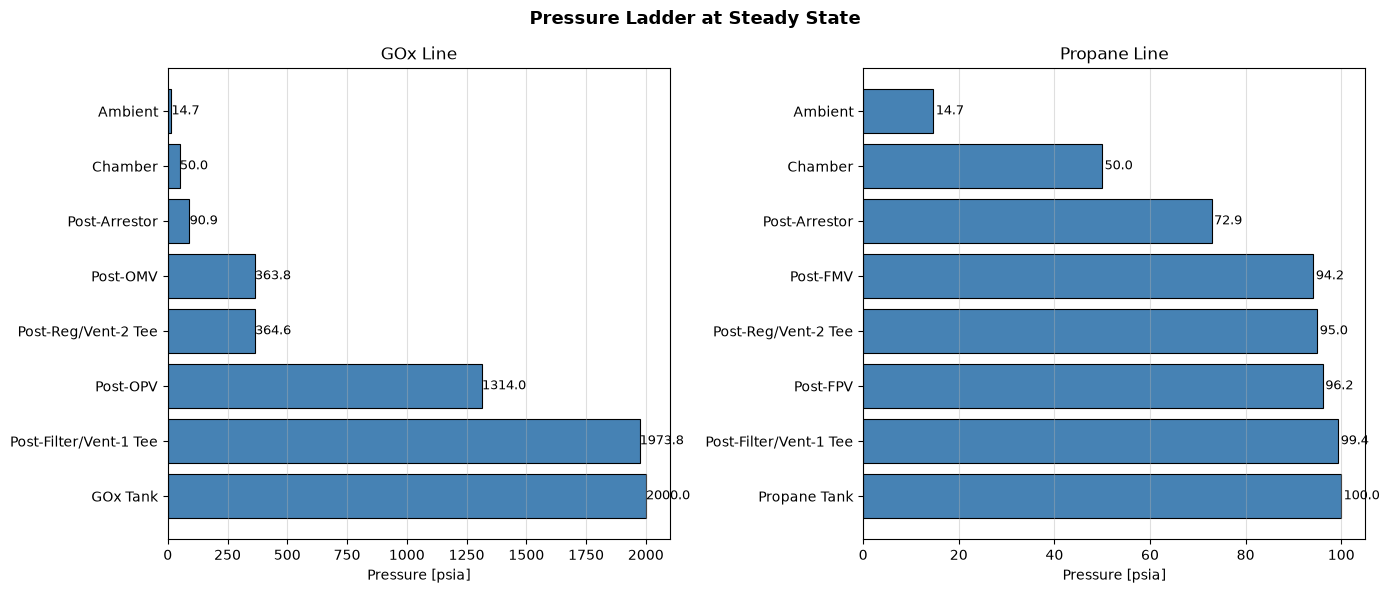

In [3]:
"""
OLD FLUID MODEL: PROPANE + GOX

METS Bipropellant Feed System — FullFlow Port
==============================================
GOx/Propane feed lines from supply tanks to combustion chamber.
Uses FullFlow for network solving and ThermoProp (CoolProp) for real
fluid properties instead of ideal gas approximations.

GOx P&ID topology:
  Tank → O-FILT → O-VENT-1(tee) → OPV → O-REG → O-VENT-2(tee) → OMV → O-ARREST → O-INJ-ORF → Chamber

Propane P&ID topology (mirrors GOx):
  Tank → F-FILT → F-VENT-1(tee) → FPV → F-REG → F-VENT-2(tee) → FMV → F-ARREST → F-INJ-ORF → Chamber

Target performance:
  mdot_total = 50 g/s,  O/F = 2.2,  Pc = 50 psia
  mdot_gox   = 34.4 g/s
  mdot_prop  = 15.6 g/s
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from fullflow import (
    Network, State, Balance,
    Component, SteadyState, Transient,
    DischargeCoefficient, Volume, Lookup,
    Colebrook,
) # taken from Saaketh's ports created from github/Linkedin
import thermoprop as tp

script_dir = Path.cwd()
PSI_TO_PA  = 6894.76


# ─────────────────────────────────────────────────────────────────────
# CUSTOM COMPONENTS
# ─────────────────────────────────────────────────────────────────────

class CvValve(Component):
    """
    Solenoid / pre-valve modeled as a Cv (US flow coefficient) restriction.

    Flow equation (gas form):
        mdot = Kv * sqrt(rho * |dP|) * sign(dP)
        Kv   = Cv * 6.309e-5 / sqrt(6894.76)

    is_open=False sets a near-infinite resistance (valve closed).
    """
    def __init__(
        self,
        name:               str,
        network:            Network,
        upstream_pressure:  State,
        downstream_pressure:State,
        density:            State,
        Cv:                 float,
        is_open:            bool  = True,
        mass_flow:          State = None,
    ):
        self._is_open = is_open
        self.setup()

    def evaluate_states(self):
        if not self._is_open:
            self.mass_flow.value = 0.0
            return
        Kv  = self.Cv.value * 6.309e-5 / np.sqrt(6894.76)
        dP  = self.upstream_pressure.value - self.downstream_pressure.value
        rho = self.density.value
        self.mass_flow.value = np.sign(dP) * Kv * np.sqrt(rho * abs(dP))

    def open(self):
        self._is_open = True

    def close(self):
        self._is_open = False


class MinorLossElement(Component):
    # Filter or flame arrestor modeled as a minor (K) loss.
    def __init__(
        self,
        name:               str,
        network:            Network,
        upstream_pressure:  State,
        downstream_pressure:State,
        density:            State,
        K:                  float,
        area:               float,
        mass_flow:          State = None,
    ):
        self.setup()

    def evaluate_states(self):
        dP  = self.upstream_pressure.value - self.downstream_pressure.value
        rho = self.density.value
        K   = self.K.value
        A   = self.area.value
        if dP == 0.0:
            self.mass_flow.value = 0.0
        else:
            self.mass_flow.value = (
                np.sign(dP) * A * np.sqrt(2.0 * rho * abs(dP) / K)
            )

class MassFlowJunction(Component):
    """
    Mass conservation at a tee junction.
    Enforces: mdot_in = mdot_main_out + mdot_branch_out

    Used where a relief vent tees off the main line.
    The junction pressure is the shared node pressure (one State
    connected to both the incoming and outgoing branches).
    """
    def __init__(
        self,
        name:           str,
        network:        Network,
        mdot_in:        State,
        mdot_main_out:  State,
        mdot_branch_out:State,
    ):
        self.residual = 0.0
        self.setup()

    def evaluate_states(self):
        self.residual = (
            self.mdot_in.value
            - self.mdot_main_out.value
            - self.mdot_branch_out.value
        )

    @property
    def balances(self):
        # We return empty; the junction residual is used by the node balance.
        return []


# ─────────────────────────────────────────────────────────────────────
# COMBUSTION EQUILIBRIUM  (ThermoProp Equilibrium — replaces c* placeholder)
# ─────────────────────────────────────────────────────────────────────

def run_combustion_equilibrium(
    OF:         float = 2.2,
    Pc_psia:    float = 50.0,
    T_ox_K:     float = 293.0,
    T_fuel_K:   float = 293.0,
) -> dict:
    """
    GOx/Propane HP equilibrium via ThermoProp.
    Returns c*, Tc, gamma_frozen, Mw, and derived orifice sizes.

    Parameters:
    ----------
    OF        : oxidizer-to-fuel mass ratio
    Pc_psia   : chamber pressure [psia]
    T_ox_K    : GOx inlet temperature [K]
    T_fuel_K  : propane inlet temperature [K]
    """
    from thermoprop import Propellant, Reactants, Equilibrium, Fluid
    import numpy as np

    Pc_pa = Pc_psia * PSI_TO_PA

    # ── Propane phase check ──────────────────────────────────────────
    prop_fluid = Fluid('propane', pressure=Pc_pa, temperature=T_fuel_K)
    P_sat_psia = prop_fluid.saturation_pressure / PSI_TO_PA
    print(f"Propane phase at {Pc_psia:.0f} psia / {T_fuel_K:.0f} K: "
          f"{prop_fluid.phase}  (Psat = {P_sat_psia:.1f} psia)")
    if prop_fluid.phase != 'Gas':
        print("  WARNING: propane is not fully gaseous at chamber inlet conditions.")
        print("  Consider raising temperature or lowering pressure.")

    # ── Equilibrium solve ────────────────────────────────────────────
    ox   = Propellant('GOX',     temperature=T_ox_K,   pressure=Pc_pa)
    fuel = Propellant('propane', temperature=T_fuel_K, pressure=Pc_pa)
    reactants = Reactants(fuels=fuel, oxidizers=ox, mixture_ratio=OF)

    eq = Equilibrium(reactants, mode='hp', pressure=Pc_pa)

    g   = eq.specific_heat_ratio_frozen
    Mw  = eq.combustion_gas.molar_mass # [kg/mol]
    Tc  = eq.temperature # [K]
    R   = 8314.0 / (Mw * 1000) # [J/kg-K]

    # Standard c* formula: c* = sqrt(R*Tc/g) / Gamma
    Gamma  = np.sqrt(g) * (2 / (g + 1)) ** ((g + 1) / (2 * (g - 1)))
    c_star = np.sqrt(R * Tc / g) / Gamma # [m/s]

    # Throat area from 0.65" diameter
    D_throat_m = 0.65 * 0.0254
    A_throat   = np.pi * D_throat_m**2 / 4

    # Total mdot from c*
    mdot_total = Pc_pa * A_throat / c_star
    mdot_ox    = mdot_total * OF   / (1 + OF)
    mdot_fuel  = mdot_total * 1.0  / (1 + OF)

    # Orifice sizing at 60 psia inlet (20% Pc pressure drop assumption)
    P_orif_pa = 60.0 * PSI_TO_PA
    dP_orif   = 10.0 * PSI_TO_PA # 20% of Pc
    Cd        = 0.72
    rho_gox   = Fluid('oxygen',  pressure=P_orif_pa, temperature=T_ox_K).density
    rho_prop  = Fluid('propane', pressure=P_orif_pa, temperature=T_fuel_K).density

    A_gox  = mdot_ox   / (Cd * np.sqrt(2 * rho_gox  * dP_orif))
    A_prop = mdot_fuel / (Cd * np.sqrt(2 * rho_prop * dP_orif))
    D_gox_mm  = np.sqrt(4 * A_gox  / np.pi) * 1000
    D_prop_mm = np.sqrt(4 * A_prop / np.pi) * 1000

    results = {
        'Tc_K':           Tc,
        'gamma_frozen':   g,
        'gamma_equil':    eq.specific_heat_ratio_equilibrium,
        'Mw_g_mol':       Mw * 1000,
        'c_star_m_s':     c_star,
        'mdot_total_g_s': mdot_total * 1000,
        'mdot_gox_g_s':   mdot_ox    * 1000,
        'mdot_prop_g_s':  mdot_fuel  * 1000,
        'D_gox_mm':       D_gox_mm,
        'D_prop_mm':      D_prop_mm,
        'top_species':    dict(sorted(
            eq.normalized_mole_fractions.items(),
            key=lambda kv: -kv[1]
        )[:6]),
    }
    return results


def print_equilibrium_results(res: dict):
    print()
    print("=" * 55)
    print("  COMBUSTION EQUILIBRIUM  (GOx/Propane, O/F=2.2, Pc=50 psia)")
    print("=" * 55)
    print(f"  Tc              = {res['Tc_K']:.1f} K  ({res['Tc_K']-273.15:.1f} °C)")
    print(f"  gamma (frozen)  = {res['gamma_frozen']:.4f}")
    print(f"  gamma (equil)   = {res['gamma_equil']:.4f}")
    print(f"  Mw              = {res['Mw_g_mol']:.2f} g/mol")
    print(f"  c*              = {res['c_star_m_s']:.1f} m/s")
    print()
    print(f"  mdot total      = {res['mdot_total_g_s']:.1f} g/s  (from 0.65 inch throat)")
    print(f"  mdot GOx        = {res['mdot_gox_g_s']:.1f} g/s")
    print(f"  mdot Propane    = {res['mdot_prop_g_s']:.1f} g/s")
    print()
    print(f"  GOx orifice D   = {res['D_gox_mm']:.2f} mm  (60 psia inlet, 10 psi dP, Cd=0.72)")
    print(f"  Propane orif. D = {res['D_prop_mm']:.2f} mm  (60 psia inlet, 10 psi dP, Cd=0.72)")
    print()
    print("  Top combustion products (mole fractions):")
    for sp, x in res['top_species'].items():
        print(f"    {sp:<12} {x:.4f}")
    print("=" * 55)
    print()


# ─────────────────────────────────────────────────────────────────────
# COMBUSTION EQUILIBRIUM  (ThermoProp Equilibrium — replaces c* placeholder)
# ─────────────────────────────────────────────────────────────────────
def run_combustion_equilibrium(
    OF:         float = 2.2,
    Pc_psia:    float = 50.0,
    T_ox_K:     float = 293.0,
    T_fuel_K:   float = 293.0,
) -> dict:
    """
    GOx/Propane HP equilibrium via ThermoProp.
    Returns c*, Tc, gamma_frozen, Mw, and derived orifice sizes.

    Also prints a propane phase check to confirm gaseous conditions.
    """
    from thermoprop import Propellant, Reactants, Equilibrium, Fluid

    Pc_pa = Pc_psia * PSI_TO_PA

    # ── Propane phase check ──────────────────────────────────────────
    prop_fluid = Fluid('propane', pressure=Pc_pa, temperature=T_fuel_K)
    P_sat_psia = prop_fluid.saturation_pressure / PSI_TO_PA
    print(f"Propane phase at {Pc_psia:.0f} psia / {T_fuel_K:.0f} K: "
          f"{prop_fluid.phase}  (Psat = {P_sat_psia:.1f} psia)")
    if prop_fluid.phase != 'Gas':
        print("  WARNING: propane is not fully gaseous at inlet conditions.")

    # ── Equilibrium solve ────────────────────────────────────────────
    ox   = Propellant('GOX',     temperature=T_ox_K,   pressure=Pc_pa)
    fuel = Propellant('propane', temperature=T_fuel_K, pressure=Pc_pa)
    reactants = Reactants(fuels=fuel, oxidizers=ox, mixture_ratio=OF)
    eq = Equilibrium(reactants, mode='hp', pressure=Pc_pa)

    g      = eq.specific_heat_ratio_frozen
    Mw     = eq.combustion_gas.molar_mass # [kg/mol]
    Tc     = eq.temperature # [K]
    R      = 8314.0 / (Mw * 1000) # [J/kg-K]

    # Standard c* formula
    Gamma  = np.sqrt(g) * (2 / (g + 1)) ** ((g + 1) / (2 * (g - 1)))
    c_star = np.sqrt(R * Tc / g) / Gamma # [m/s]

    # Throat area from 0.65" diameter
    A_throat = np.pi * (0.65 * 0.0254) ** 2 / 4

    # Total mdot and split
    mdot_total = Pc_pa * A_throat / c_star
    mdot_ox    = mdot_total * OF  / (1 + OF)
    mdot_fuel  = mdot_total * 1.0 / (1 + OF)

    # Orifice sizing: 60 psia inlet, 20% Pc dP, Cd=0.72
    P_orif_pa = 60.0 * PSI_TO_PA
    dP_orif   = 10.0 * PSI_TO_PA
    Cd        = 0.72
    rho_gox   = Fluid('oxygen',  pressure=P_orif_pa, temperature=T_ox_K).density
    rho_prop  = Fluid('propane', pressure=P_orif_pa, temperature=T_fuel_K).density

    A_gox     = mdot_ox   / (Cd * np.sqrt(2 * rho_gox  * dP_orif))
    A_prop    = mdot_fuel / (Cd * np.sqrt(2 * rho_prop * dP_orif))
    D_gox_mm  = np.sqrt(4 * A_gox  / np.pi) * 1000
    D_prop_mm = np.sqrt(4 * A_prop / np.pi) * 1000

    return {
        'Tc_K':           Tc,
        'gamma_frozen':   g,
        'gamma_equil':    eq.specific_heat_ratio_equilibrium,
        'Mw_g_mol':       Mw * 1000,
        'c_star_m_s':     c_star,
        'mdot_total_g_s': mdot_total * 1000,
        'mdot_gox_g_s':   mdot_ox    * 1000,
        'mdot_prop_g_s':  mdot_fuel  * 1000,
        'D_gox_mm':       D_gox_mm,
        'D_prop_mm':      D_prop_mm,
        'top_species':    dict(sorted(
            eq.normalized_mole_fractions.items(),
            key=lambda kv: -kv[1]
        )[:6]),
    }


def print_equilibrium_results(res: dict):
    print()
    print("=" * 55)
    print("  COMBUSTION EQUILIBRIUM  (GOx/Propane, O/F=2.2, Pc=50 psia)")
    print("=" * 55)
    print(f"  Tc              = {res['Tc_K']:.1f} K  ({res['Tc_K']-273.15:.1f} C)")
    print(f"  gamma (frozen)  = {res['gamma_frozen']:.4f}")
    print(f"  gamma (equil)   = {res['gamma_equil']:.4f}")
    print(f"  Mw              = {res['Mw_g_mol']:.2f} g/mol")
    print(f"  c*              = {res['c_star_m_s']:.1f} m/s")
    print()
    print(f"  mdot total      = {res['mdot_total_g_s']:.1f} g/s  (from 0.65\" throat)")
    print(f"  mdot GOx        = {res['mdot_gox_g_s']:.1f} g/s")
    print(f"  mdot Propane    = {res['mdot_prop_g_s']:.1f} g/s")
    print()
    print(f"  GOx orifice D   = {res['D_gox_mm']:.2f} mm  (60 psia inlet, 10 psi dP)")
    print(f"  Propane orif. D = {res['D_prop_mm']:.2f} mm  (60 psia inlet, 10 psi dP)")
    print()
    print("  Top combustion products (mole fractions):")
    for sp, x in res['top_species'].items():
        print(f"    {sp:<12} {x:.4f}")
    print("=" * 55)
    print()


# ─────────────────────────────────────────────────────────────────────
# FLUID PROPERTY HELPERS
# ─────────────────────────────────────────────────────────────────────
def gox_props(pressure: float, temperature: float) -> dict:
    """Real GOx properties via ThermoProp/CoolProp."""
    f = tp.Fluid('oxygen', pressure=pressure, temperature=temperature)
    return {
        'density':          f.density,
        'dynamic_viscosity':f.dynamic_viscosity,
        'specific_heat_ratio': f.specific_heat_ratio,
        'gas_constant':     f.gas_constant,
        'speed_of_sound':   f.speed_of_sound,
    }
def propane_props(pressure: float, temperature: float) -> dict:
    """Real propane properties via ThermoProp/CoolProp."""
    f = tp.Fluid('propane', pressure=pressure, temperature=temperature)
    return {
        'density':          f.density,
        'dynamic_viscosity':f.dynamic_viscosity,
        'specific_heat_ratio': f.specific_heat_ratio,
        'gas_constant':     f.gas_constant,
        'speed_of_sound':   f.speed_of_sound,
    }

# ─────────────────────────────────────────────────────────────────────
# FEED SYSTEM BUILDER
# ─────────────────────────────────────────────────────────────────────
def build_gox_system(
    P_tank_psia:       float = 2000.0,
    P_reg_psia:        float = 80.0, # regulator setpoint — sweep to find this
    P_chamber_psia:    float = 50.0,
    T_K:               float = 293.0,
    pipe_D:            float = 0.00635, # [m] ~1/4" tube
    # -----------------------------------------------!! PLACEHOLDER Cv/K values — REPLACE WITH DATASHEET VALUES !!----------------------------------------------------
    filt_K:            float = 2.0, # TODO: filter datasheet K
    opv_Cv:            float = 100.0, # TODO: OPV solenoid datasheet Cv
    omv_Cv:            float = 100.0, # TODO: OMV solenoid datasheet Cv
    arrest_K:          float = 5.0, # TODO: flame arrestor datasheet K
    orifice_Cd:        float = 0.72, # standard assumpution
    orifice_D_mm:      float = 9.8, # sized for 34.4 g/s at 20% Pc dP
    vent_Cv:           float = 5.0, # TODO: relief valve datasheet Cv (NC during hot fire)
) -> tuple[Network, dict]:
    """
    Build the GOx feed network in FullFlow.
    Returns:
    -------
    net     : FullFlow Network
    states  : dict of key State objects for post-processing
    """
    net  = Network("GOx")
    A_pipe    = np.pi * pipe_D**2 / 4
    A_orifice = np.pi * (orifice_D_mm * 1e-3)**2 / 4

    # ── Pressures (States) — one per node ────────────────────────────
    P_tank  = State(P_tank_psia    * PSI_TO_PA) # boundary
    P_amb   = State(14.7           * PSI_TO_PA) # boundary (ambient)
    P_cc    = State(P_chamber_psia * PSI_TO_PA) # boundary
    P_reg   = State(P_reg_psia     * PSI_TO_PA) # boundary (regulator setpoint)

    # Internal nodes — start at ambient, pressurize up
    # Note: P_pfilt = P_pv1 (filter outlet = vent-1 tee, inches of pipe, ~0 dP)
    #       P_reg  = P_pv2 (reg outlet   = vent-2 tee, inches of pipe, ~0 dP)
    P_pfilt = State(14.7 * PSI_TO_PA, bounds=(0.0, None)) # = Post-Filter = Post-Vent-1
    P_popv  = State(14.7 * PSI_TO_PA, bounds=(0.0, None)) # Post-OPV
    P_pomv  = State(14.7 * PSI_TO_PA, bounds=(0.0, None)) # Post-OMV
    P_parr  = State(14.7 * PSI_TO_PA, bounds=(0.0, None)) # Post-Arrestor

    T_tank = State(T_K)

    # ── Fluid properties via ThermoProp Lookup ────────────────────────
    # One lookup per node so density tracks local pressure
    def make_gox_lookup(name, P_state):
        return Lookup(name, net, gox_props, pressure=P_state, temperature=T_tank,
                      outputs=('density','dynamic_viscosity',
                               'specific_heat_ratio','gas_constant',
                               'speed_of_sound'))

    FL_tank  = make_gox_lookup("FL_tank",  P_tank)
    FL_pfilt = make_gox_lookup("FL_pfilt", P_pfilt) # shared: post-filter = post-vent-1
    FL_popv  = make_gox_lookup("FL_popv",  P_popv)
    FL_preg  = make_gox_lookup("FL_preg",  P_reg) # shared: post-reg = post-vent-2
    FL_pomv  = make_gox_lookup("FL_pomv",  P_pomv)
    FL_parr  = make_gox_lookup("FL_parr",  P_parr)

    # ── Branches ──────────────────────────────────────────────────────
    # P_pfilt = post-filter = post-vent-1 tee (shared node, inches of pipe)
    # P_reg   = post-reg    = post-vent-2 tee (shared node, inches of pipe)

    # Filter: tank → post-filter/vent-1 tee
    FILT = MinorLossElement("O-FILT", net,
        upstream_pressure=P_tank,  downstream_pressure=P_pfilt,
        density=FL_tank.density,   K=filt_K,   area=A_pipe)

    # Vent-1 relief valve: post-filter tee → ambient (normally closed)
    VENT1 = CvValve("O-VENT-1", net,
        upstream_pressure=P_pfilt, downstream_pressure=P_amb,
        density=FL_pfilt.density,  Cv=vent_Cv, is_open=False)

    # OPV pre-valve: post-filter tee → post-OPV
    OPV = CvValve("OPV", net,
        upstream_pressure=P_pfilt, downstream_pressure=P_popv,
        density=FL_pfilt.density,  Cv=opv_Cv,  is_open=True)

    # Regulator: post-OPV → post-reg/vent-2 tee (reg outlet = fixed boundary)
    REG = MinorLossElement("O-REG", net,
        upstream_pressure=P_popv,  downstream_pressure=P_reg,
        density=FL_popv.density,   K=0.5,      area=A_pipe)

    # Vent-2 relief valve: post-reg tee → ambient (normally closed)
    VENT2 = CvValve("O-VENT-2", net,
        upstream_pressure=P_reg,   downstream_pressure=P_amb,
        density=FL_preg.density,   Cv=vent_Cv, is_open=False)

    # OMV main valve: post-reg tee → post-OMV
    OMV = CvValve("OMV", net,
        upstream_pressure=P_reg,   downstream_pressure=P_pomv,
        density=FL_preg.density,   Cv=omv_Cv,  is_open=True)

    # Flame arrestor: post-OMV → post-arrestor
    ARREST = MinorLossElement("O-ARREST", net,
        upstream_pressure=P_pomv,  downstream_pressure=P_parr,
        density=FL_pomv.density,   K=arrest_K, area=A_pipe)

    # Injector orifice: post-arrestor → chamber
    ORF = DischargeCoefficient("O-INJ-ORF", net,
        upstream_pressure=P_parr,  downstream_pressure=P_cc,
        density=FL_parr.density,   discharge_coefficient=orifice_Cd,
        cross_sectional_area=A_orifice)

    # ── Node mass balances ────────────────────────────────────────────
    # Each internal node: mdot_in = mdot_out (steady state)
    # FullFlow Balance varies the node pressure until residual = 0

    mdot_scale = 0.05 # [kg/s] reference scale for residual normalization
    # P_pfilt node: filter in = vent1_out + opv_out
    Balance("bal_pfilt", net, variable=P_pfilt,
            function=(FILT.mass_flow - OPV.mass_flow - VENT1.mass_flow) / mdot_scale)
    # P_popv node: opv_in = reg_in
    Balance("bal_popv",  net, variable=P_popv,
            function=(OPV.mass_flow - REG.mass_flow) / mdot_scale)
    # P_reg is boundary — no balance needed (P_reg = vent2 tee = OMV inlet)
    # P_pomv node: omv_in = arrest_in
    Balance("bal_pomv",  net, variable=P_pomv,
            function=(OMV.mass_flow - ARREST.mass_flow) / mdot_scale)
    # P_parr node: arrest_in = orifice_in
    Balance("bal_parr",  net, variable=P_parr,
            function=(ARREST.mass_flow - ORF.mass_flow) / mdot_scale)

    states = {
        'P_tank':  P_tank,  'P_pfilt': P_pfilt,
        'P_popv':  P_popv,  'P_reg':   P_reg,
        'P_pomv':  P_pomv,  'P_parr':  P_parr,
        'P_cc':    P_cc,    'P_amb':   P_amb,
        'mdot_orifice': ORF.mass_flow,
        'mdot_omv':     OMV.mass_flow,
        'branches': {
            'O-FILT':    FILT.mass_flow,
            'O-VENT-1':  VENT1.mass_flow,
            'OPV':       OPV.mass_flow,
            'O-REG':     REG.mass_flow,
            'O-VENT-2':  VENT2.mass_flow,
            'OMV':       OMV.mass_flow,
            'O-ARREST':  ARREST.mass_flow,
            'O-INJ-ORF': ORF.mass_flow,
        },
    }

    return net, states


def build_propane_system(
    P_tank_psia:       float = 100.0,
    P_reg_psia:        float = 55.0,
    P_chamber_psia:    float = 50.0,
    T_K:               float = 293.0,
    pipe_D:            float = 0.00635,
    # ------------------ Same assumptions as in oxygen system, update with real values!!! -----------------------------
    filt_K:            float = 2.0, # TODO: filter datasheet K
    fpv_Cv:            float = 50.0, # TODO: FPV solenoid datasheet Cv
    fmv_Cv:            float = 50.0, # TODO: FMV solenoid datasheet Cv
    arrest_K:          float = 5.0, # TODO: flame arrestor datasheet K
    orifice_Cd:        float = 0.72,
    orifice_D_mm:      float = 5.12, # sized for 15.6 g/s at 60 psia inlet
    vent_Cv:           float = 5.0, # TODO: relief valve datasheet Cv
) -> tuple[Network, dict]:
    """
    Build the Propane feed network — mirrors GOx topology.
    P_pfilt = post-filter = post-vent-1 tee (merged, inches of pipe)
    P_reg   = post-reg    = post-vent-2 tee (fixed boundary)
    """
    net       = Network("Propane")
    A_pipe    = np.pi * pipe_D**2 / 4
    A_orifice = np.pi * (orifice_D_mm * 1e-3)**2 / 4

    P_tank  = State(P_tank_psia    * PSI_TO_PA)
    P_amb   = State(14.7           * PSI_TO_PA)
    P_cc    = State(P_chamber_psia * PSI_TO_PA)
    P_reg   = State(P_reg_psia     * PSI_TO_PA) # fixed boundary

    P_pfilt = State(14.7 * PSI_TO_PA, bounds=(0.0, None))
    P_pfpv  = State(14.7 * PSI_TO_PA, bounds=(0.0, None))
    P_pfmv  = State(14.7 * PSI_TO_PA, bounds=(0.0, None))
    P_parr  = State(14.7 * PSI_TO_PA, bounds=(0.0, None))

    T_tank = State(T_K)

    def make_prop_lookup(name, P_state):
        return Lookup(name, net, propane_props, pressure=P_state, temperature=T_tank,
                      outputs=('density','dynamic_viscosity',
                               'specific_heat_ratio','gas_constant',
                               'speed_of_sound'))

    FL_tank  = make_prop_lookup("FL_tank",  P_tank)
    FL_pfilt = make_prop_lookup("FL_pfilt", P_pfilt)
    FL_pfpv  = make_prop_lookup("FL_pfpv",  P_pfpv)
    FL_preg  = make_prop_lookup("FL_preg",  P_reg)
    FL_pfmv  = make_prop_lookup("FL_pfmv",  P_pfmv)
    FL_parr  = make_prop_lookup("FL_parr",  P_parr)

    FILT  = MinorLossElement("F-FILT", net,
        upstream_pressure=P_tank,  downstream_pressure=P_pfilt,
        density=FL_tank.density,   K=filt_K,   area=A_pipe)
    VENT1 = CvValve("F-VENT-1", net,
        upstream_pressure=P_pfilt, downstream_pressure=P_amb,
        density=FL_pfilt.density,  Cv=vent_Cv, is_open=False)
    FPV   = CvValve("FPV", net,
        upstream_pressure=P_pfilt, downstream_pressure=P_pfpv,
        density=FL_pfilt.density,  Cv=fpv_Cv,  is_open=True)
    REG   = MinorLossElement("F-REG", net,
        upstream_pressure=P_pfpv,  downstream_pressure=P_reg,
        density=FL_pfpv.density,   K=0.5,      area=A_pipe)
    VENT2 = CvValve("F-VENT-2", net,
        upstream_pressure=P_reg,   downstream_pressure=P_amb,
        density=FL_preg.density,   Cv=vent_Cv, is_open=False)
    FMV   = CvValve("FMV", net,
        upstream_pressure=P_reg,   downstream_pressure=P_pfmv,
        density=FL_preg.density,   Cv=fmv_Cv,  is_open=True)
    ARREST = MinorLossElement("F-ARREST", net,
        upstream_pressure=P_pfmv,  downstream_pressure=P_parr,
        density=FL_pfmv.density,   K=arrest_K, area=A_pipe)
    ORF   = DischargeCoefficient("F-INJ-ORF", net,
        upstream_pressure=P_parr,  downstream_pressure=P_cc,
        density=FL_parr.density,   discharge_coefficient=orifice_Cd,
        cross_sectional_area=A_orifice)

    mdot_scale = 0.05
    Balance("bal_pfilt", net, variable=P_pfilt,
            function=(FILT.mass_flow - FPV.mass_flow - VENT1.mass_flow) / mdot_scale)
    Balance("bal_pfpv",  net, variable=P_pfpv,
            function=(FPV.mass_flow - REG.mass_flow) / mdot_scale)
    Balance("bal_pfmv",  net, variable=P_pfmv,
            function=(FMV.mass_flow - ARREST.mass_flow) / mdot_scale)
    Balance("bal_parr",  net, variable=P_parr,
            function=(ARREST.mass_flow - ORF.mass_flow) / mdot_scale)

    states = {
        'P_tank':  P_tank,  'P_pfilt': P_pfilt,
        'P_pfpv':  P_pfpv,  'P_reg':   P_reg,
        'P_pfmv':  P_pfmv,  'P_parr':  P_parr,
        'P_cc':    P_cc,    'P_amb':   P_amb,
        'mdot_orifice': ORF.mass_flow,
        'mdot_fmv':     FMV.mass_flow,
        'branches': {
            'F-FILT':    FILT.mass_flow,
            'F-VENT-1':  VENT1.mass_flow,
            'FPV':       FPV.mass_flow,
            'F-REG':     REG.mass_flow,
            'F-VENT-2':  VENT2.mass_flow,
            'FMV':       FMV.mass_flow,
            'F-ARREST':  ARREST.mass_flow,
            'F-INJ-ORF': ORF.mass_flow,
        },
    }
    return net, states


def sweep_regulator(
    build_fn,
    P_reg_sweep_psia: np.ndarray,
    target_mdot:      float,
    build_kwargs:     dict = None,
) -> tuple[np.ndarray, float, float]:
    """
    Sweep regulator outlet pressure and find the setpoint that delivers
    the target orifice mass flow rate.

    Parameters:
    ----------
    build_fn         : build_gox_system or build_propane_system
    P_reg_sweep_psia : array of regulator setpoints [psia]
    target_mdot      : target orifice mass flow [kg/s]
    build_kwargs     : kwargs passed to build_fn (excluding P_reg_psia)

    Returns:
    -------
    mdot_arr         : orifice mdot at each sweep point [kg/s]
    P_req_psia       : interpolated required setpoint [psia]
    P_margin_psia    : P_req * 1.20 — suggested setpoint with 20% margin
    """
    if build_kwargs is None:
        build_kwargs = {}

    mdot_arr = np.zeros(len(P_reg_sweep_psia))

    for idx, P_reg in enumerate(P_reg_sweep_psia):
        net, states = build_fn(P_reg_psia=P_reg, **build_kwargs)
        try:
            SteadyState(net).solve(verbose=False, rtol=1e-3)
            mdot_arr[idx] = states['mdot_orifice'].value
        except Exception:
            mdot_arr[idx] = np.nan

    # Interpolate — filter out any failed (nan) points
    valid = ~np.isnan(mdot_arr)
    if valid.sum() < 2:
        print("  WARNING: fewer than 2 valid sweep points — check initial guesses")
        return mdot_arr, np.nan, np.nan

    if target_mdot < mdot_arr[valid].min() or target_mdot > mdot_arr[valid].max():
        print(f"  WARNING: target {target_mdot*1000:.1f} g/s outside sweep range "
              f"[{mdot_arr[valid].min()*1000:.1f}, {mdot_arr[valid].max()*1000:.1f}] g/s")
        return mdot_arr, np.nan, np.nan

    P_req   = float(np.interp(target_mdot, mdot_arr[valid], P_reg_sweep_psia[valid]))
    P_margin = P_req * 1.20

    return mdot_arr, P_req, P_margin


# ─────────────────────────────────────────────────────────────────────
# PLOTTING
# ─────────────────────────────────────────────────────────────────────

def print_summary(label: str, node_names: list, pressures: list,
                  branch_names: list, mdots: list):
    print(f"\n{'='*55}")
    print(f"  {label}")
    print(f"{'='*55}")
    print("  Node Pressures:")
    for name, P in zip(node_names, pressures):
        print(f"    {name:<30} {P/PSI_TO_PA:8.2f} psia")
    print("  Branch Mass Flows:")
    for name, m in zip(branch_names, mdots):
        print(f"    {name:<22} {m*1000:8.2f} g/s")


def plot_pressure_ladder(
    node_names_gox:  list, pressures_gox:  list,
    node_names_prop: list, pressures_prop: list,
):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle("Pressure Ladder at Steady State", fontsize=13, fontweight='bold')

    for ax, names, pressures, title in [
        (axes[0], node_names_gox,  pressures_gox,  "GOx Line"),
        (axes[1], node_names_prop, pressures_prop, "Propane Line"),
    ]:
        P_psia  = [p / PSI_TO_PA for p in pressures]
        colors  = ['steelblue'] * len(names)
        bars    = ax.barh(names, P_psia, color=colors, edgecolor='black', linewidth=0.8)
        ax.set_xlabel("Pressure [psia]")
        ax.set_title(title)
        ax.grid(True, axis='x', alpha=0.4)
        for bar, val in zip(bars, P_psia):
            ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                    f'{val:.1f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig(script_dir / "pressure_ladder.png", dpi=150)
    plt.show()


def plot_regulator_sweep(
    P_sweep_gox,  mdot_gox,  P_req_gox,  target_gox,
    P_sweep_prop, mdot_prop, P_req_prop, target_prop,
):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle("Regulator Pressure Sweep", fontsize=13, fontweight='bold')

    for ax, P_sweep, mdot_arr, P_req, target, label, color in [
        (axes[0], P_sweep_gox,  mdot_gox,  P_req_gox,  target_gox,  "GOx",     "steelblue"),
        (axes[1], P_sweep_prop, mdot_prop, P_req_prop, target_prop, "Propane", "firebrick"),
    ]:
        valid = ~np.isnan(mdot_arr)
        ax.plot(P_sweep[valid], mdot_arr[valid] * 1000,
                color=color, linewidth=2, label='System curve')
        ax.axhline(target * 1000, color='black', linestyle='--', linewidth=1.5,
                   label=f'Target: {target*1000:.1f} g/s')
        if not np.isnan(P_req):
            ax.axvline(P_req,        color='green',  linestyle='-',  linewidth=1.5,
                       label=f'Required: {P_req:.1f} psia')
            ax.axvline(P_req * 1.20, color='orange', linestyle=':',  linewidth=1.5,
                       label=f'+20% margin: {P_req*1.20:.1f} psia')
        ax.set_xlabel("Regulator Outlet Pressure [psia]", fontsize=11)
        ax.set_ylabel("Orifice Mass Flow [g/s]", fontsize=11)
        ax.set_title(f"{label} Line")
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.4)

    plt.tight_layout()
    plt.savefig(script_dir / "regulator_sweep.png", dpi=150)
    plt.show()


# ─────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────
if __name__ == "__main__":

    # ══════════════════════════════════════════════════════════════
    # STEP 1 — Combustion equilibrium (ThermoProp, replaces c* placeholder)
    # ══════════════════════════════════════════════════════════════
    OF        = 2.2
    P_CHAMBER = 50.0   # [psia]

    print("Running combustion equilibrium (GOx/Propane, O/F=2.2, Pc=50 psia)...")
    eq_res = run_combustion_equilibrium(OF=OF, Pc_psia=P_CHAMBER)
    print_equilibrium_results(eq_res)

    # Use equilibrium-derived mdot and orifice sizes
    MDOT_GOX  = eq_res['mdot_gox_g_s']  / 1000 # [kg/s]
    MDOT_PROP = eq_res['mdot_prop_g_s'] / 1000 # [kg/s]
    D_OX_MM   = eq_res['D_gox_mm'] # [mm]
    D_FUEL_MM = eq_res['D_prop_mm'] # [mm]

    print(f"Using mdot — GOx: {MDOT_GOX*1000:.1f} g/s  |  Propane: {MDOT_PROP*1000:.1f} g/s")
    print(f"Using orifice D — GOx: {D_OX_MM:.2f} mm  |  Propane: {D_FUEL_MM:.2f} mm")
    print()

    # ── Common kwargs (excluding P_reg_psia which the sweep varies) ──
    # !! All Cv/K values are PLACEHOLDERS — replace with datasheet values !!
    # Note: orifice diameters sized at 60 psia inlet / 10 psi dP with real CoolProp density.
    # Required reg pressure will shift significantly when real Cv/K values replace placeholders.
    gox_kwargs = dict(
        P_tank_psia    = 2000.0,
        P_chamber_psia = P_CHAMBER,
        orifice_Cd     = 0.72,
        orifice_D_mm   = D_OX_MM, # from equilibrium sizing
        filt_K         = 2.0, # TODO: filter datasheet K
        opv_Cv         = 100.0, # TODO: OPV solenoid datasheet Cv
        omv_Cv         = 100.0, # TODO: OMV solenoid datasheet Cv
        arrest_K       = 5.0, # TODO: flame arrestor datasheet K
    )
    prop_kwargs = dict(
        P_tank_psia    = 100.0,
        P_chamber_psia = P_CHAMBER,
        orifice_Cd     = 0.72,
        orifice_D_mm   = D_FUEL_MM, # from equilibrium sizing
        filt_K         = 2.0, # TODO: filter datasheet K
        fpv_Cv         = 50.0, # TODO: FPV solenoid datasheet Cv
        fmv_Cv         = 50.0, # TODO: FMV solenoid datasheet Cv
        arrest_K       = 5.0, # TODO: flame arrestor datasheet K
    )

    # ── Regulator sweep ──────────────────────────────────────────────
    # NOTE: with placeholder Cv=100 (OMV) and Cv=50 (FMV), required reg
    # pressures are high because valves dominate resistance. These numbers
    # will drop significantly once real (higher) Cv values are plugged in.
    P_sweep_gox  = np.linspace(60,  600, 40)   # wide range for placeholder Cv values
    P_sweep_prop = np.linspace(51,  95,  30)    # propane tank only 100 psia

    print("\nSweeping GOx regulator pressure...")
    mdot_gox, P_req_gox, P_margin_gox = sweep_regulator(
        build_gox_system, P_sweep_gox, MDOT_GOX, gox_kwargs)

    print("Sweeping Propane regulator pressure...")
    mdot_prop, P_req_prop, P_margin_prop = sweep_regulator(
        build_propane_system, P_sweep_prop, MDOT_PROP, prop_kwargs)

    print()
    print("=" * 55)
    print("  REGULATOR SIZING RESULTS  (placeholder Cv/K values)")
    print("=" * 55)
    print(f"  GOx   required setpoint : {P_req_gox:.1f} psia")
    print(f"  GOx   +20% margin       : {P_margin_gox:.1f} psia")
    print()
    print(f"  Propane required setpoint: {P_req_prop:.1f} psia")
    print(f"  Propane +20% margin      : {P_margin_prop:.1f} psia")
    print("=" * 55)
    print("  !! Results shift when real Cv/K values are plugged in !!")
    print("=" * 55)

    plot_regulator_sweep(
        P_sweep_gox, mdot_gox, P_req_gox, MDOT_GOX,
        P_sweep_prop, mdot_prop, P_req_prop, MDOT_PROP,
    )

    # ── Solve at required setpoints and print summary ────────────────
    print("\nSolving at required regulator setpoints...")

    # Guard: if sweep couldn't find a solution, fall back to sweep max
    # so the system still builds and plots (avoids nan -> CoolProp crash)
    P_solve_gox  = P_req_gox  if not np.isnan(P_req_gox)  else float(P_sweep_gox[-1])
    P_solve_prop = P_req_prop if not np.isnan(P_req_prop) else float(P_sweep_prop[-1])

    if np.isnan(P_req_gox):
        print(f"  NOTE: GOx target outside sweep range — plotting at {P_solve_gox:.1f} psia (sweep max)")
    if np.isnan(P_req_prop):
        print(f"  NOTE: Propane cannot deliver {MDOT_PROP*1000:.1f} g/s with current Cv values")
        print(f"  and 100 psia tank. Plotting at {P_solve_prop:.1f} psia. Action: use higher-Cv")
        print(f"  FMV/FPV valves or raise tank pressure once hardware is selected.")

    gox_net, gox_states   = build_gox_system(P_reg_psia=P_solve_gox,   **gox_kwargs)
    SteadyState(gox_net).solve(verbose=False, rtol=1e-3)

    prop_net, prop_states = build_propane_system(P_reg_psia=P_solve_prop, **prop_kwargs)
    SteadyState(prop_net).solve(verbose=False, rtol=1e-3)

    # Node pressure lists for ladder plot
    gox_node_names  = ['GOx Tank','Post-Filter/Vent-1 Tee','Post-OPV',
                        'Post-Reg/Vent-2 Tee','Post-OMV','Post-Arrestor',
                        'Chamber','Ambient']
    gox_pressures   = [s.value for s in [
        gox_states['P_tank'],  gox_states['P_pfilt'],
        gox_states['P_popv'],  gox_states['P_reg'],
        gox_states['P_pomv'],  gox_states['P_parr'],
        gox_states['P_cc'],    gox_states['P_amb'],
    ]]

    prop_node_names = ['Propane Tank','Post-Filter/Vent-1 Tee','Post-FPV',
                       'Post-Reg/Vent-2 Tee','Post-FMV','Post-Arrestor',
                       'Chamber','Ambient']
    prop_pressures  = [s.value for s in [
        prop_states['P_tank'],  prop_states['P_pfilt'],
        prop_states['P_pfpv'],  prop_states['P_reg'],
        prop_states['P_pfmv'],  prop_states['P_parr'],
        prop_states['P_cc'],    prop_states['P_amb'],
    ]]

    print_summary(
        "GOx Steady State",
        gox_node_names, gox_pressures,
        list(gox_states['branches'].keys()),
        [s.value for s in gox_states['branches'].values()],
    )
    print_summary(
        "Propane Steady State",
        prop_node_names, prop_pressures,
        list(prop_states['branches'].keys()),
        [s.value for s in prop_states['branches'].values()],
    )

    plot_pressure_ladder(
        gox_node_names,  gox_pressures,
        prop_node_names, prop_pressures,
    )